In [1]:
from google.colab import files
uploaded=files.upload()

Saving international_matches.csv to international_matches.csv


         date home_team     away_team home_team_continent away_team_continent  \
0  1993-08-08   Bolivia       Uruguay       South America       South America   
1  1993-08-08    Brazil        Mexico       South America       North America   
2  1993-08-08   Ecuador     Venezuela       South America       South America   
3  1993-08-08    Guinea  Sierra Leone              Africa              Africa   
4  1993-08-08  Paraguay     Argentina       South America       South America   

   home_team_fifa_rank  away_team_fifa_rank  home_team_total_fifa_points  \
0                   59                   22                            0   
1                    8                   14                            0   
2                   35                   94                            0   
3                   65                   86                            0   
4                   67                    5                            0   

   away_team_total_fifa_points  home_team_score  ...  sh

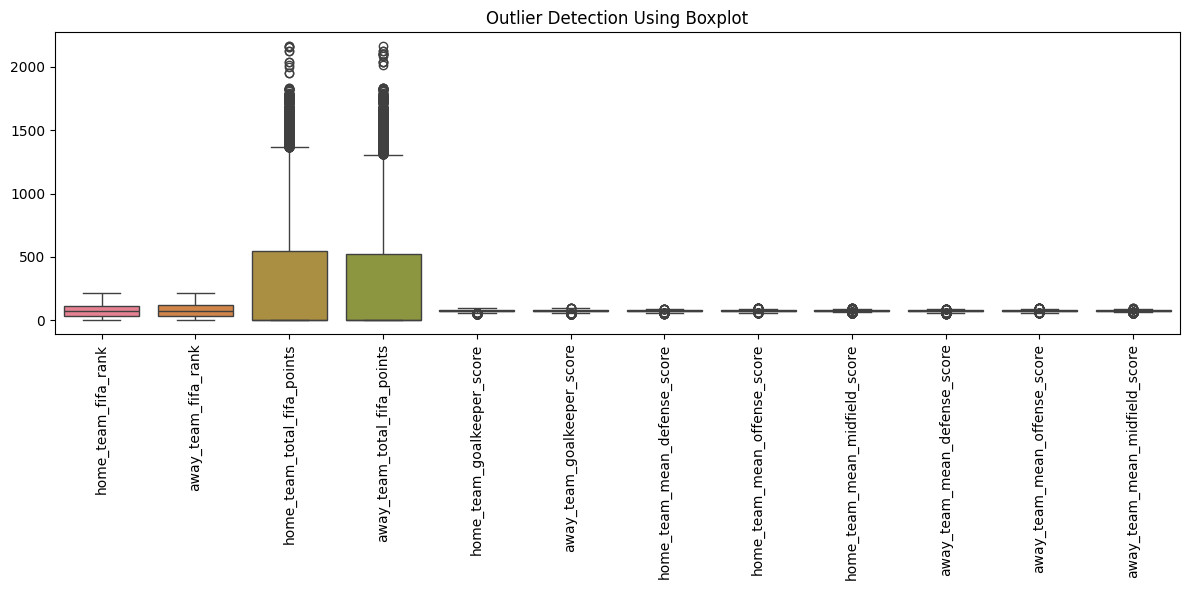

Empty DataFrame
Columns: [date, home_team, away_team, home_team_continent, away_team_continent, home_team_fifa_rank, away_team_fifa_rank, home_team_total_fifa_points, away_team_total_fifa_points, home_team_score, away_team_score, tournament, city, country, neutral_location, shoot_out, home_team_result, home_team_goalkeeper_score, away_team_goalkeeper_score, home_team_mean_defense_score, home_team_mean_offense_score, home_team_mean_midfield_score, away_team_mean_defense_score, away_team_mean_offense_score, away_team_mean_midfield_score]
Index: []

[0 rows x 25 columns]
     home_team_score  away_team_score home_team_result calculated_result  \
104                0                0             Lose              Draw   
194                1                1              Win              Draw   
275                2                2              Win              Draw   
429                1                1             Lose              Draw   
438                2                2        

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# STEP 2: LOAD DATASET

df = pd.read_csv("/content/international_matches.csv")


# STEP 3: DISPLAY FIRST FIVE ROWS

print(df.head())


# STEP 4: DISPLAY LAST FIVE ROWS

print(df.tail())


# STEP 5: CHECK SHAPE

print("Dataset Shape:", df.shape)


# STEP 6: CHECK COLUMN NAMES

print(df.columns)


# STEP 7: CHECK DATA TYPES

print(df.dtypes)


# STEP 8: CHECK DATASET INFORMATION

df.info()


# STEP 9: STATISTICAL SUMMARY

print(df.describe())


# STEP 10: CHECK MISSING VALUES

print(df.isnull().sum())


# STEP 11: TOTAL MISSING VALUES

print("Total Missing Values:",
      df.isnull().sum().sum())


# STEP 12: MISSING VALUE PERCENTAGE

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage.sort_values(ascending=False))


# STEP 13: CHECK DUPLICATES

print("Duplicate Rows:", df.duplicated().sum())


# STEP 14: REMOVE DUPLICATES

df = df.drop_duplicates()


# STEP 15: REMOVE EXTRA SPACES

text_columns = df.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df[col] = df[col].str.strip()


# STEP 16: CONVERT DATE COLUMN

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)


# STEP 17: CHECK CATEGORICAL VALUES

print(df['home_team'].unique())

print(df['away_team'].unique())

print(df['tournament'].unique())

print(df['home_team_result'].unique())

print(df['shoot_out'].unique())


# STEP 18: HANDLE MISSING VALUES

# Identify numerical columns
numeric_columns = df.select_dtypes(
    include=np.number
).columns

# Check missing values in numerical columns
print(df[numeric_columns].isnull().sum())

# Team rating columns
rating_columns = [
    'home_team_goalkeeper_score',
    'away_team_goalkeeper_score',
    'home_team_mean_defense_score',
    'home_team_mean_offense_score',
    'home_team_mean_midfield_score',
    'away_team_mean_defense_score',
    'away_team_mean_offense_score',
    'away_team_mean_midfield_score'
]

# Preserve missing ratings for EDA.
# Optional median imputation is performed later
# only if required for a machine learning model.


# STEP 19: CHECK INVALID NEGATIVE VALUES

for col in numeric_columns:
    print(
        col,
        "Negative Values:",
        (df[col] < 0).sum()
    )


# STEP 20: CHECK OUTLIERS USING IQR METHOD

# IQR = Q3 - Q1
# Lower Bound = Q1 - 1.5 * IQR
# Upper Bound = Q3 + 1.5 * IQR

iqr_columns = [
    'home_team_fifa_rank',
    'away_team_fifa_rank',
    'home_team_total_fifa_points',
    'away_team_total_fifa_points',
    'home_team_goalkeeper_score',
    'away_team_goalkeeper_score',
    'home_team_mean_defense_score',
    'home_team_mean_offense_score',
    'home_team_mean_midfield_score',
    'away_team_mean_defense_score',
    'away_team_mean_offense_score',
    'away_team_mean_midfield_score'
]

for col in iqr_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outliers:", len(outliers))


# STEP 21: VISUALIZE OUTLIERS USING BOXPLOT

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[iqr_columns])

plt.xticks(rotation=90)
plt.title("Outlier Detection Using Boxplot")
plt.tight_layout()
plt.show()


# STEP 22: CHECK INCONSISTENT MATCH SCORES

print(
    df[
        (df['home_team_score'] < 0) |
        (df['away_team_score'] < 0)
    ]
)


# STEP 23: CHECK MATCH RESULT CONSISTENCY

df['calculated_result'] = np.select(
    [
        df['home_team_score'] > df['away_team_score'],
        df['home_team_score'] < df['away_team_score']
    ],
    ['Win', 'Lose'],
    default='Draw'
)

print(
    df[
        df['calculated_result'] != df['home_team_result']
    ][[
        'home_team_score',
        'away_team_score',
        'home_team_result',
        'calculated_result',
        'shoot_out'
    ]].head()
)


# STEP 24: FEATURE ENGINEERING

# Extract year
df['year'] = df['date'].dt.year

# Extract month
df['month'] = df['date'].dt.month

# Extract day
df['day'] = df['date'].dt.day

# Calculate total goals
df['total_goals'] = (
    df['home_team_score'] +
    df['away_team_score']
)

# Calculate goal difference
df['goal_difference'] = (
    df['home_team_score'] -
    df['away_team_score']
)


# STEP 25: FINAL DATASET VERIFICATION

print("\nFINAL DATASET SHAPE:")
print(df.shape)

print("\nFINAL MISSING VALUES:")
print(df.isnull().sum())

print("\nFINAL DUPLICATES:")
print(df.duplicated().sum())

print("\nFINAL DATA TYPES:")
print(df.dtypes)

print("\nFINAL DATASET:")
print(df.head())


# EXPORT CLEANED DATASET

df.to_csv(
    "cleaned_international_matches.csv",
    index=False
)

print("\nDATA CLEANING COMPLETED!")
